In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_func import *
import AR_interpolations_func
importlib.reload(AR_interpolations_func)
from AR_interpolations_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_plotting import *
import AR_interpolations_plotting
importlib.reload(AR_interpolations_plotting)
from AR_interpolations_plotting  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *



import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Global parameter

In [3]:
dir_save_data = r'H:\commun\Utilisateur FNO\Nathan\Conference\JDD 2025\Figures'

## Plot a PaP signal

In [25]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'
dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'

dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

Error : there is no treated data


AttributeError: 'NoneType' object has no attribute 'delay_tot'

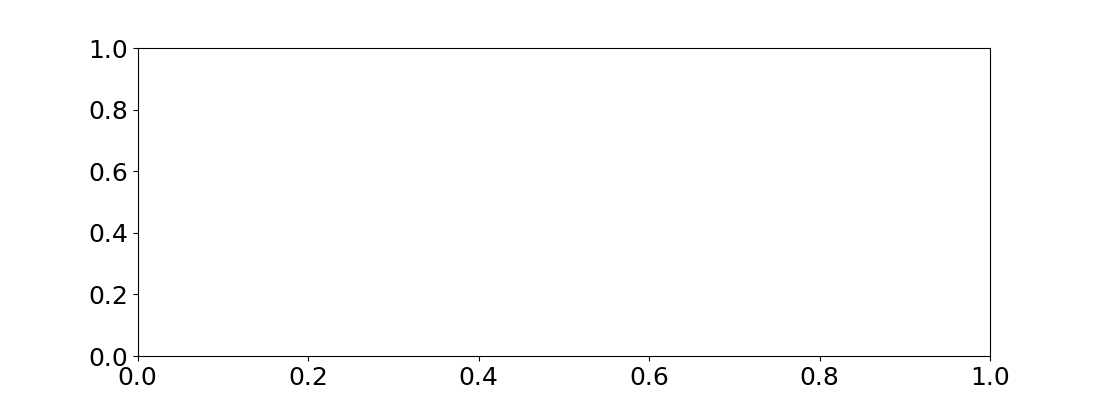

In [26]:
alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*alpha_DTT_dsigma,  color = 'black')


ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
ax.grid('on')

plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP signal.svg')
   

## Quality factor study

In [ ]:
dir_root_v3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\Simulations_treated'
fname_data_simu = 'Simulation_treated.csv'



#kernel = 'thin_plate_spline'
Simu_data, Lda_RBF, E_RBF, W_RBF, Aire_RBF = get_simu_data_and_interpolate(dir_root_v3, fname_data_simu, kernel='linear')

h_1D = 21


H_lisse = np.linspace(0, 40, 200)
D_lisse = np.linspace(0, 160, 200)
HH_lisse, DD_lisse = np.meshgrid( H_lisse, D_lisse)
points_lisses = np.array(list(zip(HH_lisse.flatten(), DD_lisse.flatten())))




dir_root_ND = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\ND_measurements'
fname_Exp = 'Nd_measurements_data.dat'
Exp_data = get_ND_measures(dir_root_ND, fname_Exp)


d_guess, h_guess = 100, 20 #initial (D,h) guess in nm

AR_estimation_1D_Lda_SPR(Exp_data, Lda_RBF, h=h_1D)
AR_estimation_1D_Aire_SPR(Exp_data, Aire_RBF, h=h_1D)
AR_estimation_2D(Exp_data, Lda_RBF, Aire_RBF, d_guess=d_guess, h_guess=h_guess)
Gamma_surf_estimation(Exp_data, W_RBF)


## Make the plot
fig, ax = plt.subplots(figsize = (9,4))

for key in Exp_data :
    spectra = Exp_data[key]

    if spectra['Q'] != 0 :
            
        ax.scatter(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], c = 'black')
        ax.errorbar(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], yerr = spectra['Q_err'], color='black')
        

ax.set_xlabel(r'D/h')
ax.set_ylabel('Q')
ax.set_ylim(bottom = 0)
ax.grid()
plt.tight_layout()
plt.show()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)

#plt.savefig('Q_factor_study.svg')


## Acoustic sensitivity

In [ ]:
Data={}


Data['AR2.3 - NDd zone 3'] = {}


Data['AR2.3 - NDd zone 3']['lda_SPR'] = 640e-9


Data['AR2.3 - NDd zone 3']['color'] = '#488f31'


dir_root_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3'
dir_root_treated_data_2 = dir_root_2 + r'\Extinction variation calculation'
dir_root_exp_traces_2 = dir_root_2 + r'\PaP_study'
fname_acoustic_2 = 'Treated_acoustic_data'
fname_thermic_2 = 'Treated_thermic_data'

Data['AR2.3 - NDd zone 3']['acoustic'] = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_acoustic_2)
Data['AR2.3 - NDd zone 3']['thermic']  = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_thermic_2)
Data['AR2.3 - NDd zone 3']['All traces'] = get_all_raw_traces(dir_root_exp_traces_2)
Data['AR2.3 - NDd zone 3']['All traces'] = reorder_all_traces_dic(Data['AR2.3 - NDd zone 3']['All traces'])




fig, ax = plt.subplots(figsize=(9, 4))


ax.errorbar(Data['AR2.3 - NDd zone 3']['acoustic']['lambda_probe'],Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac'], yerr = np.abs(Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_err']), color = Data['AR2.3 - NDd zone 3']['color'],  label = 'AR2.3 - NDd zone 3' )

ax.axhline(0, color='black')
ax.axvline(Data['AR2.3 - NDd zone 3']['lda_SPR']*1e9, color = 'black', linestyle='--')

ax.set_xlabel(r'$\lambda_\mathrm{probe}$ (nm)')
ax.set_ylabel(r'$\Delta \sigma_\mathrm{ext, initial}$ (nm$^2$)')
ax.text(0.42, 0.1, r'$\lambda_\mathrm{SPR}$', transform=ax.transAxes)

fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()

os.chdir(dir_save_data)

#plt.savefig('Acoustic_sensitivity_study.svg')

## Acoustic gif

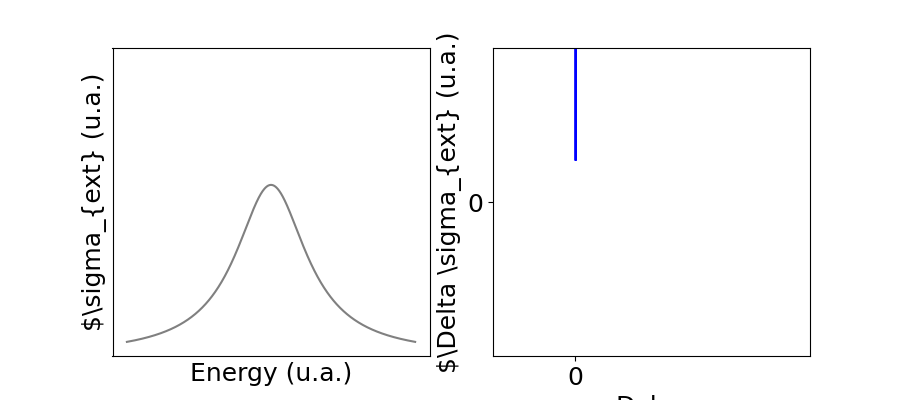

In [8]:
animation_name = 'SPR_and_DTT_signal_acoustic'

fig, ax = plt.subplots(ncols=2, figsize=(9,4))


imax=100

#Set (x,y) limits for axes

ymin_spr, ymax_spr = (0,  6)


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -1, 1

top_lim = 3
bottom_limit  = -0.5



Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.05
delta_Ec =0.03

tau = 800/3
T = 100
phi = 0


#Shape variation of the nanosidk
alpha = 0.2 # Dilatation coefficient


#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0




ax[0].set_ylim((ymin_spr, ymax_spr))
ax[0].set_xticks([])  # Remove x-axis ticks
ax[0].set_yticks([])  # Remove y-axis ticks
ax[0].set_xlabel('Energy (u.a.)')
ax[0].set_ylabel(r'$\sigma_{ext} (u.a.)')


ax[1].set_ylim((ymin_dtt, ymax_dtt))
ax[1].set_xlim((xmin_dtt, xmax_dtt))
ax[1].set_xticks([0])  # Remove x-axis ticks
ax[1].set_yticks([0])  # Remove y-axis ticks
ax[1].set_xlabel('Delay')
ax[1].set_ylabel(r'$\Delta \sigma_{ext} (u.a.)')


scat = ax[0].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey')

scat = ax[1].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='blue')



Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :
    ax[1].cla()
    ax[0].cla()
    x_probe = Energy[400]


    ### SPR plot 

    ax[0].set_ylim((ymin_spr, ymax_spr))
    ax[0].set_xticks([])  # Remove x-axis ticks
    ax[0].set_yticks([])  # Remove y-axis ticks
    ax[0].set_xlabel('Energy ')
    ax[0].set_ylabel(r'$\sigma_{ext}$')

    width, height = 0.2, 0.1
    x_ini, y_ini = 0.85 - width/2, 0.85 - height/2
    x_c, y_c = x_ini - width/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi), y_ini - height/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)

    rect_disk = mpatches.Rectangle((x_c, y_c), 0.2*(1+ np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi) ), 0.1*(1+np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)), transform=ax[0].transAxes, facecolor='#ffc507ff', edgecolor='black')
    ax[0].add_patch(rect_disk)

    scat = ax[0].plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*Osc1(Time[i], delta_Ec, tau, T, phi), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0),color='blue')
    ax[0].plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    ax[0].plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')

    ax[0].axvline(x_probe, color='green', linestyle='--')
    ax[0].text(0.15, 0.8, r'$\lambda_\mathrm{probe}$', color='green',  transform=ax[0].transAxes)

    ## DTT plot
    ax[1].set_ylim((ymin_dtt, ymax_dtt))
    ax[1].set_xlim((xmin_dtt, xmax_dtt))
    ax[1].set_xticks([0])  # Remove x-axis ticks
    ax[1].set_yticks([0])  # Remove y-axis ticks
    ax[1].set_xlabel('Delay')
    ax[1].set_ylabel(r'$\Delta \sigma_{ext}$')
    ax[1].tick_params(axis='x', direction='in', pad=-20)

    scat = ax[1].plot(Time[:i+1], Lorentz(x_probe, E_c+np.array(Time>0)[:i+1]*(Osc1(Time[:i+1], delta_Ec, tau, T, phi)), w + np.array(Time>0)[:i+1]*Osc1(Time[:i+1], delta_w, tau, T, phi), A, y0)-Lorentz(x_probe, E_c, w , A, y0),color='black')

 



    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()